<a href="https://colab.research.google.com/github/Ossel14/atelier1-deeplearning/blob/main/notebooks/01_regression_nyse.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Atelier 1 — Deep Learning avec PyTorch

## Partie 1 : Régression — Dataset NYSE

### Objectif
Construire un réseau de neurones profond (MLP) capable de prédire
le prix de clôture d'une action à partir de données historiques.

### Étape 1 : Chargement et exploration du dataset

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch

print("PyTorch version :", torch.__version__)
print("GPU disponible :", torch.cuda.is_available())

PyTorch version : 2.11.0+cu130
GPU disponible : True


In [ ]:
import kagglehub
import pandas as pd
from pathlib import Path

# Télécharger le fichier directement depuis Kaggle
file_path = kagglehub.dataset_download(
    "dgawlik/nyse",
    path="prices-split-adjusted.csv"
)

# Charger les données
df = pd.read_csv(file_path)

print("Dimensions du dataset :", df.shape)
print("\nColonnes :", df.columns.tolist())

display(df.head())

100%|██████████| 15.6M/15.6M [00:00<00:00, 52.3MB/s]

Extracting zip of prices-split-adjusted.csv...


Dimensions du dataset : (851264, 7)

Colonnes : ['date', 'symbol', 'open', 'close', 'low', 'high', 'volume']


,date,symbol,open,close,low,high,volume
0,2016-01-05,WLTW,123.430000,125.839996,122.309998,126.250000,2163600.0
1,2016-01-06,WLTW,125.239998,119.980003,119.940002,125.540001,2386400.0
2,2016-01-07,WLTW,116.379997,114.949997,114.930000,119.739998,2489500.0
3,2016-01-08,WLTW,115.480003,116.620003,113.500000,117.440002,2006300.0
4,2016-01-11,WLTW,117.010002,114.970001,114.089996,117.330002,1408600.0


In [ ]:
print("Informations générales :")
df.info()

print("\nStatistiques descriptives :")
display(df.describe())

Informations générales :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 851264 entries, 0 to 851263
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   date    851264 non-null  object 
 1   symbol  851264 non-null  object 
 2   open    851264 non-null  float64
 3   close   851264 non-null  float64
 4   low     851264 non-null  float64
 5   high    851264 non-null  float64
 6   volume  851264 non-null  float64
dtypes: float64(5), object(2)
memory usage: 45.5+ MB

Statistiques descriptives :


,open,close,low,high,volume
count,851264.000000,851264.000000,851264.000000,851264.000000,8.512640e+05
mean,64.993618,65.011913,64.336541,65.639748,5.415113e+06
std,75.203893,75.201216,74.459518,75.906861,1.249468e+07
min,1.660000,1.590000,1.500000,1.810000,0.000000e+00
25%,31.270000,31.292776,30.940001,31.620001,1.221500e+06
50%,48.459999,48.480000,47.970001,48.959999,2.476250e+06
75%,75.120003,75.139999,74.400002,75.849998,5.222500e+06
max,1584.439941,1578.130005,1549.939941,1600.930054,8.596434e+08


## 2. Analyse exploratoire des données (EDA)

L'objectif de cette étape est de comprendre la structure du dataset NYSE,
d'identifier les types de variables, de détecter les valeurs manquantes
et d'étudier les caractéristiques des données financières avant
la construction du modèle de régression.

In [ ]:
# Dimensions du dataset
print("Dimensions :", df.shape)

# Types des variables
print("\nTypes des variables :")
print(df.dtypes)

# Nombre d'entreprises différentes
print("\nNombre d'entreprises :", df["symbol"].nunique())

# Période couverte
df["date"] = pd.to_datetime(df["date"])

print("\nDate minimale :", df["date"].min())
print("Date maximale :", df["date"].max())

# Aperçu du dataset
display(df.head())

Dimensions : (851264, 7)

Types des variables :
date       object
symbol     object
open      float64
close     float64
low       float64
high      float64
volume    float64
dtype: object

Nombre d'entreprises : 501

Date minimale : 2010-01-04 00:00:00
Date maximale : 2016-12-30 00:00:00


,date,symbol,open,close,low,high,volume
0,2016-01-05,WLTW,123.430000,125.839996,122.309998,126.250000,2163600.0
1,2016-01-06,WLTW,125.239998,119.980003,119.940002,125.540001,2386400.0
2,2016-01-07,WLTW,116.379997,114.949997,114.930000,119.739998,2489500.0
3,2016-01-08,WLTW,115.480003,116.620003,113.500000,117.440002,2006300.0
4,2016-01-11,WLTW,117.010002,114.970001,114.089996,117.330002,1408600.0


In [ ]:
# Valeurs manquantes
missing_values = df.isnull().sum()

print("Valeurs manquantes par colonne :")
display(missing_values)

# Pourcentage de valeurs manquantes
missing_percent = (df.isnull().sum() / len(df)) * 100

print("\nPourcentage de valeurs manquantes :")
display(missing_percent)

# Détection des doublons
print("\nNombre de lignes dupliquées :", df.duplicated().sum())

# Détection des doublons par entreprise et date
print(
    "Doublons (date, symbol) :",
    df.duplicated(subset=["date", "symbol"]).sum()
)

Valeurs manquantes par colonne :


,0
date,0
symbol,0
open,0
close,0
low,0
high,0
volume,0



Pourcentage de valeurs manquantes :


,0
date,0.0
symbol,0.0
open,0.0
close,0.0
low,0.0
high,0.0
volume,0.0



Nombre de lignes dupliquées : 0
Doublons (date, symbol) : 0


,date,open,close,low,high,volume
count,851264,851264.000000,851264.000000,851264.000000,851264.000000,8.512640e+05
mean,2013-07-21 02:56:29.294037760,64.993618,65.011913,64.336541,65.639748,5.415113e+06
min,2010-01-04 00:00:00,1.660000,1.590000,1.500000,1.810000,0.000000e+00
25%,2011-10-19 00:00:00,31.270000,31.292776,30.940001,31.620001,1.221500e+06
50%,2013-08-02 00:00:00,48.459999,48.480000,47.970001,48.959999,2.476250e+06
75%,2015-04-24 00:00:00,75.120003,75.139999,74.400002,75.849998,5.222500e+06
max,2016-12-30 00:00:00,1584.439941,1578.130005,1549.939941,1600.930054,8.596434e+08
std,NaN,75.203893,75.201216,74.459518,75.906861,1.249468e+07


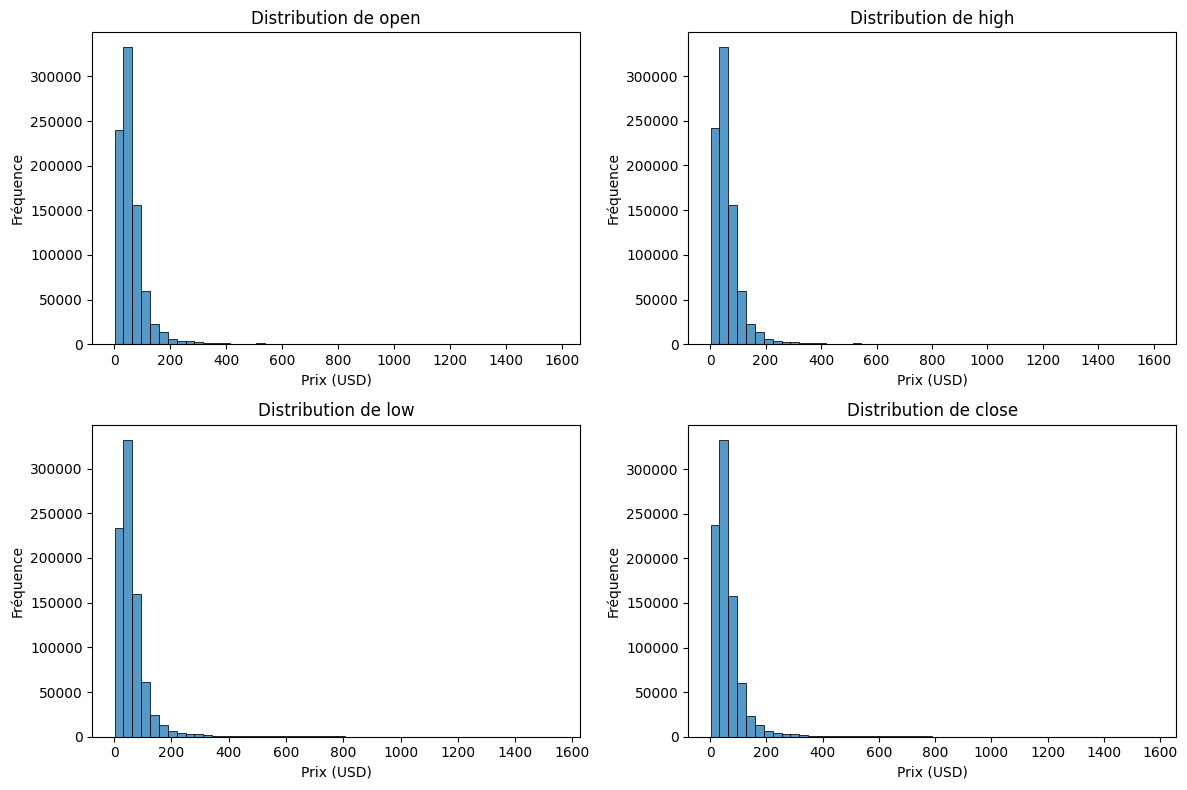

In [ ]:
# Statistiques descriptives
display(df.describe())

# Visualisation des distributions
price_columns = ["open", "high", "low", "close"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flatten(), price_columns):
    sns.histplot(df[col].dropna(), bins=50, ax=ax)
    ax.set_title(f"Distribution de {col}")
    ax.set_xlabel("Prix (USD)")
    ax.set_ylabel("Fréquence")

plt.tight_layout()
plt.show()
